# 12 · Modelo lineal: regresión Ridge

La regresión Ridge es el primer modelo de la comparación. Actúa como referencia interpretable frente a los modelos no lineales posteriores. Su objetivo es comprobar si una relación lineal tipo ridge entre las variables mejora la estimación del ratio.

Ridge es una regresión lineal con una penalización sobre el tamaño de los coeficientes (Hoerl y Kennard, 1970). Su función de pérdida es el error cuadrático (L2) más:

$$\min_{\beta} \sum_{i}(y_i - \hat{y}_i)^2 + \alpha \sum_{j}\beta_j^2$$

El primer término mide el error de ajuste. El segundo penaliza los coeficientes grandes. El parámetro $\alpha$ regula la intensidad de la penalización: con $\alpha = 0$ equivale a una regresión lineal ordinaria.

Para mi problema, las variables de entrada presentan una estructura jerárquica. Cada máquina pertenece a una única familia de máquinas. Cada familia de producto pertenece a una única línea de producto. Tras la codificación one-hot, parte de las columnas pueden resultar redundantes entre sí.

Esta redundancia genera multicolinealidad. En una regresión ordinaria provoca coeficientes inestables y de gran magnitud. La penalización de Ridge estabiliza los coeficientes y reparte el efecto entre las variables relacionadas.

Además, la codificación one-hot genera un número elevado de columnas. La penalización reduce también el riesgo de sobreajuste.

**Limitaciones.** Ridge solo capta relaciones lineales y no modela interacciones entre variables (p. ej. máquina × tipo de fase) salvo que se definan explícitamente.

Puntos del notebook:

1. Cargar datos y definir variables
2. Preparar las variables para Ridge
3. Entrenar y validar con los 3 folds (ratio)
4. Entrenar y validar con los 3 folds (log(ratio))
5. Comparar con el baseline B0
6. Guardar las predicciones de validación
7. Predicciones de test

- **Entrada:** `data/modeling/df_split.parquet`, `data/modeling/folds.csv` y `data/predictions/b0.parquet`
- **Salida:** `data/predictions/ridge_valid.parquet` y `data/predictions/ridge_test.parquet`

In [49]:
import sys
from pathlib import Path

# Raíz del repositorio (la carpeta que contiene src/), para poder importar src
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

from src.modelado import (OBJETIVO, VARIABLES, VARIABLES_CATEGORICAS, VARIABLES_NUMERICAS,
                          ajustar_y_predecir, buscar_hiperparametros, cargar_datos_modelado,
                          evaluar_en_folds, metricas, obtener_fold, rellenar_desconocidas)
from src.rutas import FIGURES, PREDICTIONS

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

## 1. Cargar datos y definir variables

Las variables (`VARIABLES_CATEGORICAS`, `VARIABLES_NUMERICAS`) y la variable objetivo (`OBJETIVO = "ratio"`) están
definidas en `src/modelado.py`, comunes a todos los modelos.

In [50]:
df, MESES_VALIDACION = cargar_datos_modelado()

print("Valores nulos por variable:")
print(df[VARIABLES + [OBJETIVO]].isna().sum())

Valores nulos por variable:
CodigoMaquina        0
Familia Maquinas     0
TipoFase             0
Línea Producto      81
Família Producto    94
TiempoPrevisto       0
Quantity             0
ratio                0
dtype: int64


In [51]:
sin_linea = df[df["Línea Producto"].isna()]

print(sin_linea["split"].value_counts(), "\n")             # ¿desarrollo o test?
print(sin_linea["Familia Maquinas"].value_counts(), "\n")   # ¿en qué máquinas?
print(sin_linea["ratio"].describe())                        # ¿su ratio es raro?

split
test          48
desarrollo    33
Name: count, dtype: int64 

Familia Maquinas
TCN    32
MTP    23
TPU    12
CON     7
CV      4
C5      3
Name: count, dtype: int64 

count    81.000000
mean      1.940601
std       1.797971
min       0.374074
25%       0.870760
50%       1.430794
75%       1.897755
max       7.267222
Name: ratio, dtype: float64


Este modelo no acepta NaN, así que los agrupo con una etiqueta "Desconocida".

In [52]:
df = rellenar_desconocidas(df)
print(df[VARIABLES_CATEGORICAS].isna().sum())   # ahora debería salir todo a 0

CodigoMaquina       0
Familia Maquinas    0
TipoFase            0
Línea Producto      0
Família Producto    0
dtype: int64


## 2. Preparar las variables

- **Variables categóricas** (`CodigoMaquina`, `Familia Maquinas`, `TipoFase`, `Línea Producto`, `Família Producto`):
  codificación one-hot. Las categorías con menos de 30 fases en entrenamiento se agrupan como infrecuentes. Las
  categorías no observadas en entrenamiento (p. ej. la máquina CM19) se asignan a ese mismo grupo.
- **Variables numéricas** (`TiempoPrevisto`, `Quantity`): transformación logarítmica y estandarización (media 0 y
  desviación típica 1). El logaritmo recoge la relación no lineal observada entre la duración de la fase y el ratio:
  en el estudio del ratio se detectó el comportamiento logarítmico del ratio respecto al tiempo dedicado a la fase.

Todas las transformaciones se ajustan únicamente con los datos de entrenamiento de cada fold. Se evita así cualquier
fuga de información hacia la validación.

Para facilitar el código, la comparación entre modelos y evitar errores entre folds, trabajo con `ColumnTransformer`
y `Pipeline` de scikit-learn: el preprocesado y el modelo se entrenan juntos en cada fold.

In [53]:
preprocesado = ColumnTransformer([
    ("categoricas",
     OneHotEncoder(min_frequency=30, handle_unknown="infrequent_if_exist"),
     VARIABLES_CATEGORICAS),
    ("numericas",
     Pipeline([("log", FunctionTransformer(np.log1p)),
               ("escala", StandardScaler())]),
     VARIABLES_NUMERICAS),
])

modelo_ridge = Pipeline([
    ("preprocesado", preprocesado),
    ("ridge", Ridge()),     # alpha se elige con validación (secciones 3 y 4)
])

## 3. Entrenar y validar Ridge en los 3 folds (ratio)

Se prueban seis valores de alpha, cada uno 10 veces mayor que el anterior, con los mismos 3 folds. El criterio de
elección es el menor MAE medio en validación (RMSE como apoyo).

In [54]:
ALPHAS = [0.01, 0.1, 1, 10, 100, 1000]

ajuste_alpha = buscar_hiperparametros(modelo_ridge, [{"ridge__alpha": a} for a in ALPHAS],
                                      df, MESES_VALIDACION)
ajuste_alpha = ajuste_alpha.rename(columns={"ridge__alpha": "alpha"})
print(ajuste_alpha.round(3))

     alpha  MAE_train  MAE_medio_val  RMSE_medio           MAE_por_fold
0     0.01      0.874          0.868       1.235  [0.935, 0.831, 0.838]
1     0.10      0.874          0.868       1.235  [0.935, 0.831, 0.838]
2     1.00      0.874          0.868       1.235  [0.935, 0.831, 0.837]
3    10.00      0.875          0.868       1.236  [0.937, 0.832, 0.835]
4   100.00      0.877          0.873       1.241  [0.941, 0.839, 0.838]
5  1000.00      0.891          0.888       1.267  [0.949, 0.858, 0.857]


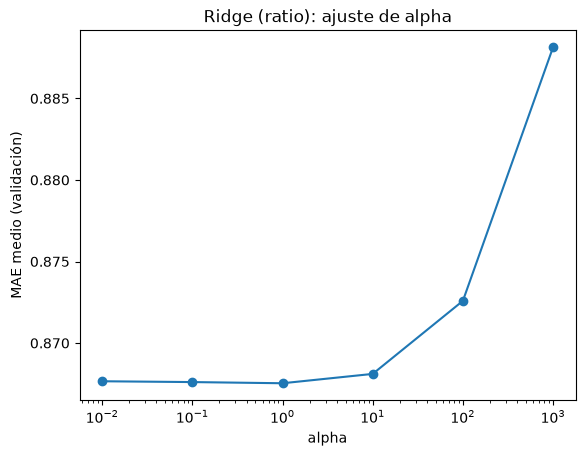

In [55]:
plt.plot(ajuste_alpha["alpha"], ajuste_alpha["MAE_medio_val"], marker="o")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("MAE medio (validación)")
plt.title("Ridge (ratio): ajuste de alpha")
plt.savefig(FIGURES / "12_ridge_alpha_ratio.png", dpi=200, bbox_inches="tight")
plt.show()

Configuración final del modelo Ridge (ratio):

In [56]:
modelo_ridge.set_params(ridge__alpha=1.0)

resultados_ridge, pred_ratio = evaluar_en_folds(modelo_ridge, df, MESES_VALIDACION)
print(resultados_ridge.round(3))
print(f"\nMAE medio:  {resultados_ridge['MAE'].mean():.3f}")
print(f"RMSE medio: {resultados_ridge['RMSE'].mean():.3f}")

          bloque  n_train    MAE   RMSE    n
0  valid 2026-02     8890  0.935  1.310  915
1  valid 2026-03     9805  0.831  1.203  993
2  valid 2026-04    10798  0.837  1.192  963

MAE medio:  0.868
RMSE medio: 1.235


### Resultados (objetivo: ratio)

Se ha entrenado y validado Ridge en los 3 folds temporales (febrero, marzo y abril de 2026). En cada fold el modelo se
entrena desde cero con los meses anteriores al de validación.

**Ajuste de alpha**

- Entre 0,01 y 10 el MAE medio se mantiene constante (0,872). Las diferencias por fold son de milésimas.
- A partir de 100 el error empieza a subir, hasta 0,892 con alpha = 1.000. Con tanta penalización el modelo pierde
  información de las variables.

El modelo es robusto a la elección de alpha dentro de la meseta. Se adopta **alpha = 1**, valor central de la meseta.

El error es bastante estable entre folds. Marzo y abril dan valores muy parecidos. Febrero es el fold con más error, y
también el que entrena con menos meses. Con los datos disponibles no se puede saber si la diferencia se debe al menor
volumen de entrenamiento o a algo propio de ese mes.

El RMSE sigue siendo claramente mayor que el MAE (relación ≈ 1,43). Esto indica que se mantienen errores grandes en
una parte de las fases, en línea con la cola del ratio vista en el análisis de la variable objetivo.

## 4. Entrenar y validar con los 3 folds (log(ratio))

Al trabajar con el log(ratio) es importante comparar en la misma escala. A la predicción del modelo se le aplica la
exponencial para devolverla a escala ratio antes de calcular las métricas:

ratio → log(ratio) → Ridge aprende (train) → Ridge predice (valid) → exp → ratio predicho

In [57]:
ajuste_alpha_log = buscar_hiperparametros(modelo_ridge, [{"ridge__alpha": a} for a in ALPHAS],
                                          df, MESES_VALIDACION, log=True)
ajuste_alpha_log = ajuste_alpha_log.rename(columns={"ridge__alpha": "alpha"})
print(ajuste_alpha_log.round(3))

     alpha  MAE_train  MAE_medio_val  RMSE_medio           MAE_por_fold
0     0.01      0.825          0.848       1.302  [0.918, 0.811, 0.816]
1     0.10      0.825          0.848       1.302  [0.918, 0.811, 0.816]
2     1.00      0.825          0.849       1.302  [0.918, 0.812, 0.816]
3    10.00      0.827          0.850       1.305   [0.92, 0.814, 0.815]
4   100.00      0.834          0.856       1.315   [0.925, 0.821, 0.82]
5  1000.00      0.850          0.877       1.349  [0.939, 0.846, 0.846]


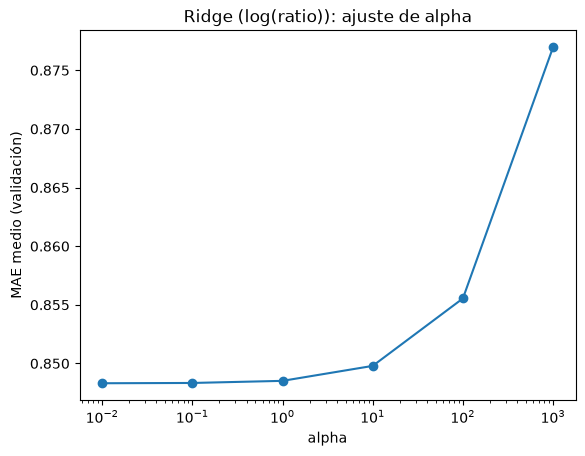

In [58]:
plt.plot(ajuste_alpha_log["alpha"], ajuste_alpha_log["MAE_medio_val"], marker="o")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("MAE medio (validación)")
plt.title("Ridge (log(ratio)): ajuste de alpha")
plt.savefig(FIGURES / "12_ridge_alpha_log.png", dpi=200, bbox_inches="tight")
plt.show()

También en esta versión se han probado los seis valores de alpha con los mismos 3 folds temporales. El criterio de
elección es el menor MAE medio en validación.

Las dos versiones muestran el mismo comportamiento. Para valores bajos de alpha el MAE medio se mantiene prácticamente
constante: forma una meseta. A partir de alpha = 100 el error aumenta. Con tanta penalización el modelo pierde parte
de la información de las variables.

El comportamiento se repite en los 3 folds, así que la elección no depende de un mes concreto.

Se adopta **alpha = 1** en ambas versiones. Es un valor situado dentro de la meseta, donde el error es mínimo. Usar el
mismo alpha en las dos versiones permite que la única diferencia entre ellas sea la variable objetivo.

Los resultados indican que el modelo es robusto a la elección de alpha: dentro de la meseta, las diferencias de MAE
son de milésimas.

Modelo final con Ridge (log(ratio)):

In [59]:
modelo_ridge.set_params(ridge__alpha=1.0)

resultados_ridge_log, pred_log = evaluar_en_folds(modelo_ridge, df, MESES_VALIDACION, log=True)
print(resultados_ridge_log.round(3))
print(f"\nMAE medio:  {resultados_ridge_log['MAE'].mean():.3f}")
print(f"RMSE medio: {resultados_ridge_log['RMSE'].mean():.3f}")

          bloque  n_train    MAE   RMSE    n
0  valid 2026-02     8890  0.918  1.380  915
1  valid 2026-03     9805  0.812  1.266  993
2  valid 2026-04    10798  0.816  1.261  963

MAE medio:  0.849
RMSE medio: 1.302


El modelo se ha entrenado con log(ratio) y alpha = 1. Las predicciones se han devuelto a escala ratio con la
exponencial antes de calcular las métricas, así que los resultados se pueden comparar directamente con los de la
versión ratio.

El error es estable entre folds. Marzo y abril dan valores muy parecidos. Febrero vuelve a ser el fold con más error,
igual que en la versión ratio.

La relación RMSE/MAE es de 1,302: se mantienen errores grandes en una parte de las fases.

A tener en cuenta: al deshacer el logaritmo con la exponencial, la predicción tiende a situarse cerca de la mediana y
no de la media. Esto puede favorecer al MAE y penalizar al RMSE. Se valorará en la comparación entre versiones.

## 5. Comparar con el baseline B0

In [60]:
b0 = pd.read_parquet(PREDICTIONS / "b0.parquet")   # predicciones B0

filas = []
for i, mes in enumerate(MESES_VALIDACION):
    _, valid_b0 = obtener_fold(b0, mes)
    m_b0 = metricas(valid_b0["ratio"], valid_b0["pred_B0"])
    filas.append({
        "fold":            mes,
        "MAE_B0":          m_b0["MAE"],
        "MAE_ratio":       resultados_ridge.loc[i, "MAE"],
        "MAE_log(ratio)":  resultados_ridge_log.loc[i, "MAE"],
        "RMSE_B0":         m_b0["RMSE"],
        "RMSE_ratio":      resultados_ridge.loc[i, "RMSE"],
        "RMSE_log(ratio)": resultados_ridge_log.loc[i, "RMSE"],
    })

comparacion = pd.DataFrame(filas).set_index("fold")
comparacion.loc["media"] = comparacion.mean()

# Mejora respecto a B0 (%), en MAE
comparacion["mejora_MAE_ratio_%"] = (1 - comparacion["MAE_ratio"] / comparacion["MAE_B0"]) * 100
comparacion["mejora_MAE_log(ratio)_%"] = (1 - comparacion["MAE_log(ratio)"] / comparacion["MAE_B0"]) * 100
comparacion.round(3)

,MAE_B0,MAE_ratio,MAE_log(ratio),RMSE_B0,RMSE_ratio,RMSE_log(ratio),mejora_MAE_ratio_%,mejora_MAE_log(ratio)_%
fold,,,,,,,,
2026-02,1.140,0.935,0.918,1.779,1.310,1.380,17.946,19.441
2026-03,1.086,0.831,0.812,1.672,1.203,1.266,23.498,25.219
2026-04,1.092,0.837,0.816,1.680,1.192,1.261,23.354,25.308
media,1.106,0.868,0.849,1.711,1.235,1.302,21.543,23.263


Viendo la comparación, las dos versiones mejoran B0 en los 3 folds.

En MAE (métrica principal), log(ratio) gana a ratio en los 3 folds, por pocas centésimas.

En RMSE ocurre lo contrario: ratio gana a log(ratio) en los 3 folds.



## 6. Guardar las predicciones de validación

In [61]:
pred_ridge_valid = pred_ratio.rename(columns={"pred": "pred_ridge_ratio"})
pred_ridge_valid["pred_ridge_log"] = pred_log["pred"].values

pred_ridge_valid.to_parquet(PREDICTIONS / "ridge_valid.parquet", index=False)
print(pred_ridge_valid.shape)
pred_ridge_valid.head()

(2871, 5)


,IDMOTask,mes_orden,ratio,pred_ridge_ratio,pred_ridge_log
0,503758e9-3758-40dc-8b3f-fca57d71de65,2026-02,0.577435,2.190573,1.829184
1,89527791-13b3-45d8-826a-dd93ee1b37e8,2026-02,0.877084,2.542389,2.033783
2,1722d5f7-ebef-41e4-aec3-26b2a7e98a25,2026-02,3.017857,1.900120,1.498654
3,7dd63da0-13f4-42ad-82bf-33ac3650ac3e,2026-02,1.947847,1.185700,1.058644
4,6bffabd3-318b-4244-b70a-f832e9c13c1d,2026-02,1.354938,1.375503,1.245540


In [62]:
for nombre, col in [("predicción ratio", "pred_ridge_ratio"), ("predicción log", "pred_ridge_log"),
                    ("ratio real", "ratio")]:
    print(f"{nombre:17} | media {pred_ridge_valid[col].mean():.3f} | mediana {pred_ridge_valid[col].median():.3f}")

predicción ratio  | media 1.877 | mediana 1.871
predicción log    | media 1.573 | mediana 1.516
ratio real        | media 1.968 | mediana 1.550


>A tener en cuenta: el modelo en log aprende el valor central del log(ratio). Al deshacer el logaritmo con la exponencial, la predicción se sitúa cerca de la mediana del ratio y no de su media, que es mayor por la cola de ratios altos. Esto puede favorecer al MAE, que premia acertar la fase típica, y penalizar al RMSE, que castiga más los errores grandes de la cola. Además, las predicciones quedarán de media por debajo del ratio real, lo que importa si se suman tiempos de varias fases. Se valorará en la comparación entre versiones.

El prototipo está pensado para estimar la desviación de cada fase de forma individual. Por este motivo, el MAE se considera la métrica principal: mide cuánto se equivoca el modelo en la fase típica. A su vez la versión log(ratio) saca peores resultados en fases con ratios elevados, cabe destacar que los ratios elevados es muy posible que tenga ruido intratable. 

Con este criterio, la versión log(ratio) ofrece el mejor resultado. Sus predicciones se sitúan cerca de la mediana del ratio y no de su media.

## 7. Predicciones de test

Con los hiperparámetros congelados en validación (alpha = 1), se reentrena con todo el conjunto de desarrollo y se
predice el test. Aquí solo se guardan las predicciones: el test se evalúa una única vez, en el notebook 15.

In [63]:
desarrollo = df[df["split"] == "desarrollo"]
test = df[df["split"] == "test"]

pred_ridge_test = pd.DataFrame({
    "IDMOTask":         test["IDMOTask"].values,
    "mes_orden":        test["mes_orden"].values,
    "ratio":            test[OBJETIVO].values,
    "pred_ridge_ratio": ajustar_y_predecir(modelo_ridge, desarrollo, test),
    "pred_ridge_log":   ajustar_y_predecir(modelo_ridge, desarrollo, test, log=True),
})

print(pred_ridge_test.shape, pred_ridge_test.isna().sum().sum())
pred_ridge_test.to_parquet(PREDICTIONS / "ridge_test.parquet", index=False)

(2385, 5) 0
